In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing              import StandardScaler, MinMaxScaler
from sklearn.cluster                    import DBSCAN

from sklearn.decomposition              import PCA
import umap.umap_ as umap
import pacmap

from utils.Preprocessing                import PreProcessData
from utils.plotFigures                  import linePlot, lineAndScatterPlot, scatterPlot3D, scatterPlot2D
from clustering.clusteringTimeSeries    import ClusteringTimeSeries

# Preprocessing

In [2]:
preData = PreProcessData()
preData.dataLoading(typeFile='h5')
df      = preData.splitTimeSeries()

scaler  = MinMaxScaler() 
preData.normalizeData(scaler);

## Split time series graph

In [3]:
linePlot(data   = df, 
         x      = 'tiempo', 
         y      = 'corriente(A)', 
         color  = 'trajectory')

# Clustering

In [4]:
# Declarate models for clustering and dimensionality reduction for manipulable variables

dfManipulableVar = preData.scaledCrusher1[preData.manipulatedCr1]

clusteringModels    = {'umap':   DBSCAN(eps=2.2, min_samples=100, n_jobs=-1),
                       'pacmap': DBSCAN(eps=3.5, min_samples=100, n_jobs=-1)} 

dimReductionModels  = {'umap':   umap.UMAP(n_components=2),
                       'pacmap': pacmap.PaCMAP(n_components=2, save_tree=True)}

In [5]:
Clusters = ClusteringTimeSeries(data                = preData.crusher1, 
                                dataNormalized      = dfManipulableVar, 
                                clusteringModels    = clusteringModels, 
                                dimReductionModels  = dimReductionModels)

In [6]:
# Train dimensinality reduction models wiht a trajectory
Clusters.train(trainTrajectory='15')

In [7]:
# Clusters are calculated in embedding space
Clusters.getResults()

100%|██████████| 6/6 [01:12<00:00, 12.02s/it]


## Graphs of the results

In [ ]:
Clusters.plotEmbedding(nfigures=2)

### Comparison of clusters by dimensionality reduction algorithm

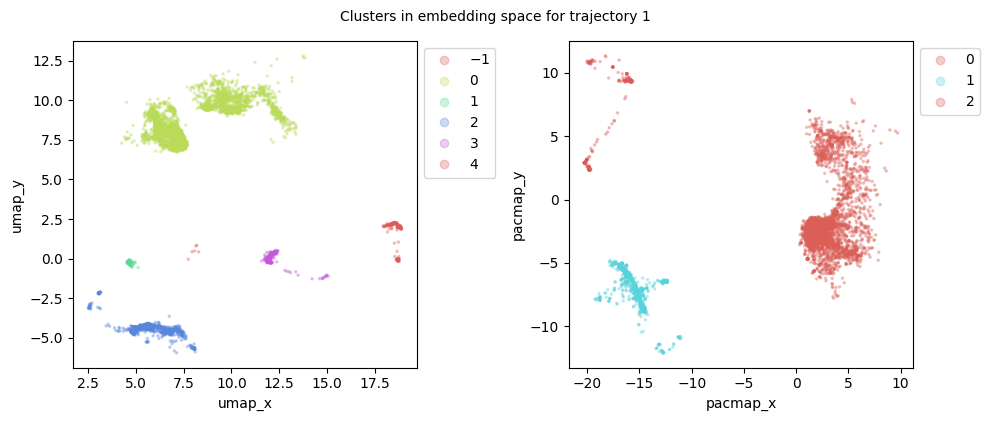

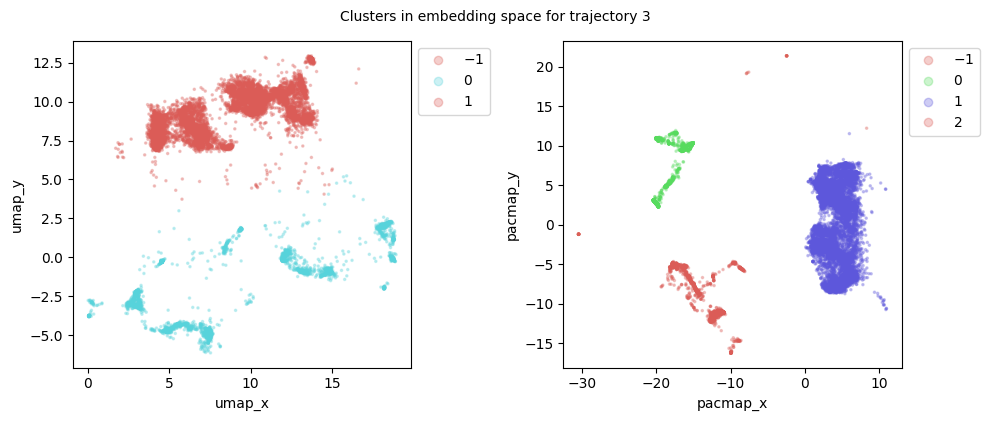

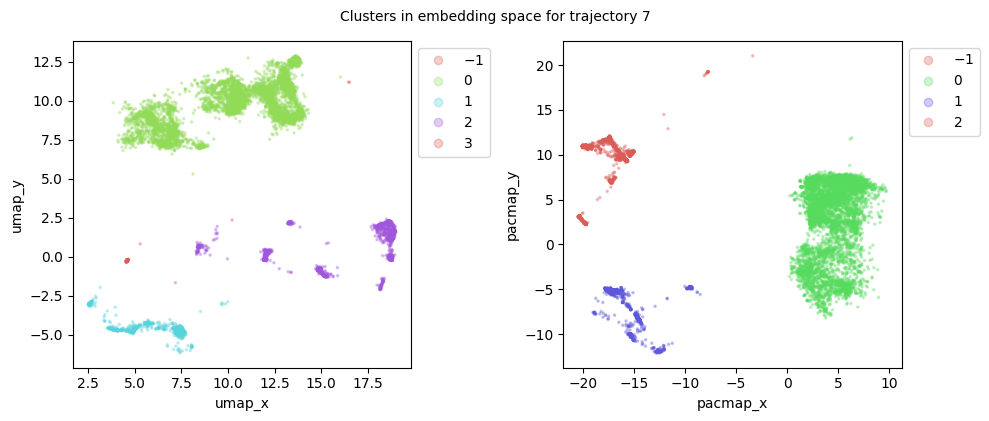

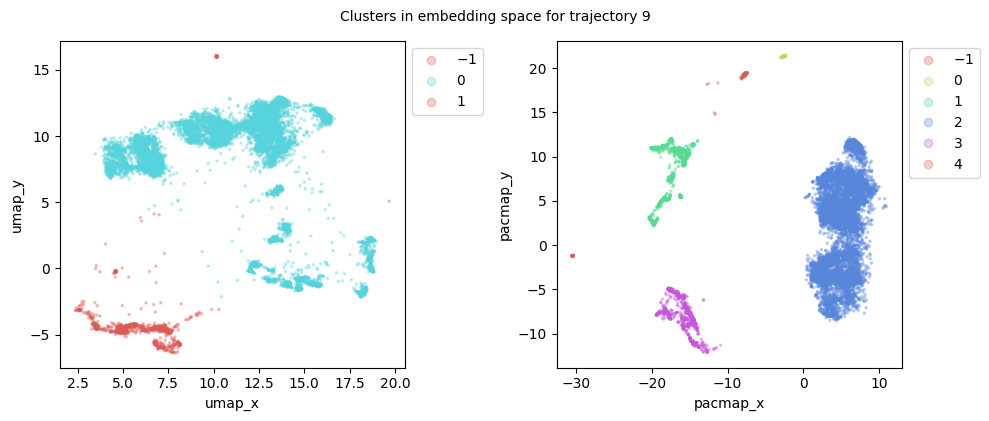

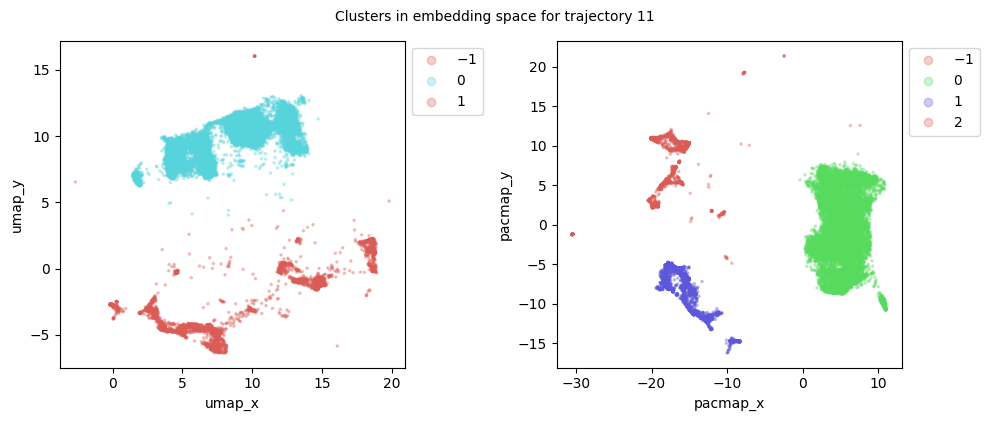

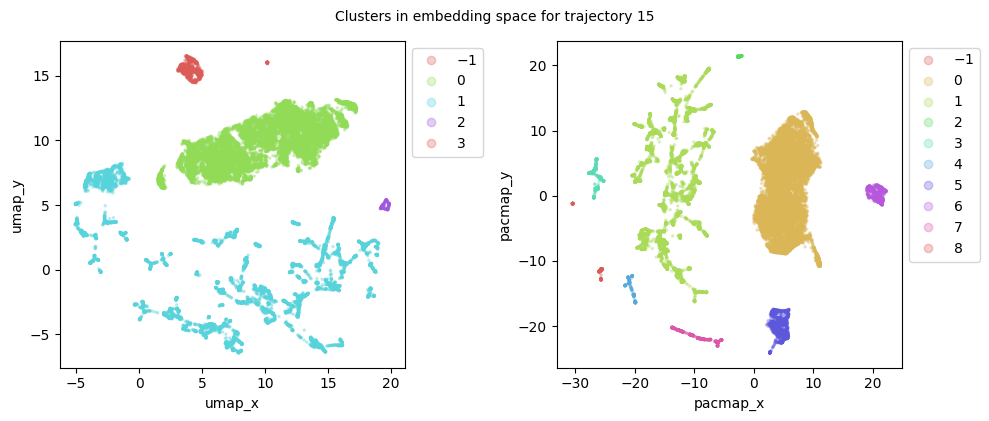

In [9]:
Clusters.plotResults(nfigures=6)

In [ ]:
variable = dfManipulableVar.columns[2]
Clusters.plotVarByCluster(idxTrajectory = 4, 
                          variable      = variable, 
                          algorithm     = 'pacmap')

### Clusters in embedding space

In [ ]:
Clusters.plotFigure('scatter2D', 
                    idxTrajectory   = 5, 
                    idxVariable     = 10, 
                    algorithm       = 'pacmap')

### Time series colored by clusters

In [ ]:
Clusters.plotFigure('lineplot', 
                    idxTrajectory   = 1, 
                    idxVariable     = 0, 
                    algorithm       = 'pacmap')

# Clusters Comparison

In [10]:
dfSimilarClusters = Clusters.getSimilarClusters(algorithm = 'pacmap', 
                                                threshold = 5)

In [ ]:
idxGroupCluster = 33
scatterPlot2D(data  = dfSimilarClusters[dfSimilarClusters['group']==idxGroupCluster], 
              x     = 'pacmap_x', 
              y     = 'pacmap_y', 
              color = 'label',
              title = 'Similar clusters')

## Work in progress

In [11]:
dfResults = dfSimilarClusters.drop(columns=['pacmap_x', 'pacmap_y']).drop_duplicates().reset_index(drop=True)
dfResults

,cluster,trajectory,label,group
0,0,1,"cluster: 0, trajectory: 1",0
1,1,3,"cluster: 1, trajectory: 3",0
2,1,1,"cluster: 1, trajectory: 1",1
3,2,3,"cluster: 2, trajectory: 3",1
4,2,1,"cluster: 2, trajectory: 1",2
...,...,...,...,...
67,2,15,"cluster: 2, trajectory: 15",33
68,3,9,"cluster: 3, trajectory: 9",34
69,0,15,"cluster: 0, trajectory: 15",34
70,0,11,"cluster: 0, trajectory: 11",35


In [12]:
Groups = dfResults['group'].unique()
removeGroups = Groups.copy()

realClusters = []
for group in Groups:

    if np.isin(group, removeGroups).item():
        dfFiltered = dfResults[dfResults['group']==group]
        trajectory1, trajectory2 = dfFiltered['trajectory']
        cluster1, cluster2 = dfFiltered['cluster']

        groups = dfResults[((dfResults['cluster']==cluster1)&
                            (dfResults['trajectory']==trajectory1))|
                            ((dfResults['cluster']==cluster2)&
                            (dfResults['trajectory']==trajectory2))]['group'].unique()
        
        similarClusters = dfResults[dfResults['group'].isin(groups)].drop_duplicates(subset='label')

        realClusters.append(similarClusters)
        removeGroups = removeGroups[~np.isin(removeGroups, groups)]

In [13]:
unifiedClusters = pd.DataFrame(columns=dfSimilarClusters.columns)
for cluster in range(len(realClusters)):
    dfUnified = pd.merge(dfSimilarClusters, realClusters[cluster], on=['cluster','trajectory','label','group'])
    dfUnified['real cluster'] = cluster
    unifiedClusters = pd.concat([unifiedClusters, dfUnified], ignore_index=True)

C:\Users\CAEX\AppData\Local\Temp\ipykernel_18756\1543698142.py:5: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



In [ ]:
unifiedClusters['real cluster'].unique()

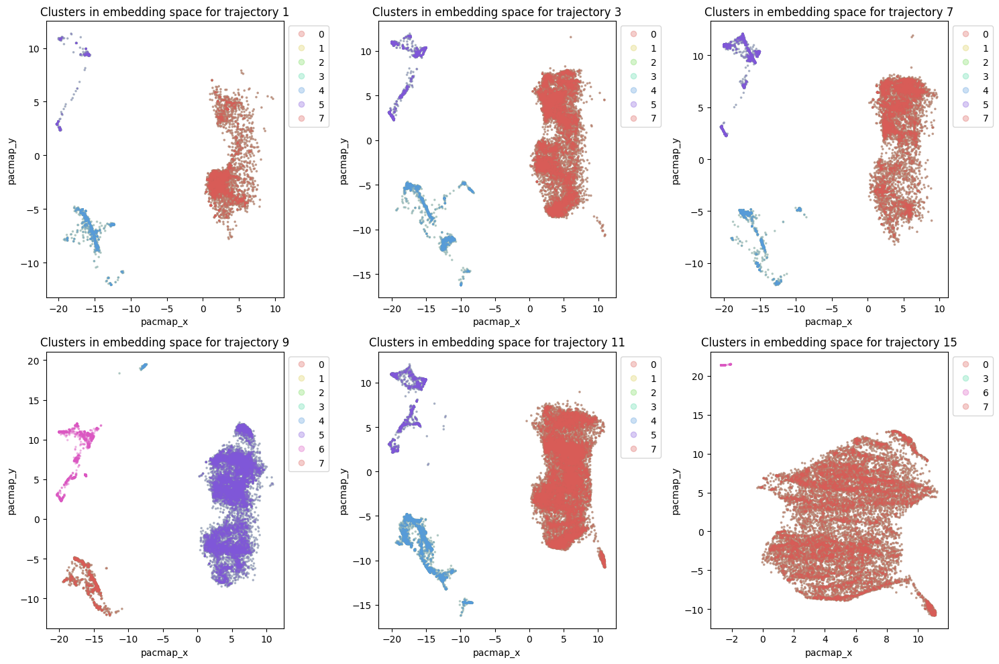

In [14]:
import matplotlib.pyplot as plt
from matplotlib.colors              import ListedColormap
import seaborn as sns
cmap  = ListedColormap(sns.color_palette("hls", 256).as_hex())


fig, axes  = plt.subplots(nrows   =  2, 
                            ncols   = 3, 
                            figsize = (15, 10))
algorithm = 'pacmap'
trajectories = unifiedClusters.trajectory.unique()
for j, ax in enumerate(axes.flatten()):
    data = unifiedClusters[unifiedClusters['trajectory']==trajectories[j]]
    scatterplot = ax.scatter(x      = data[f'{algorithm}_x'], 
                            y      = data[f'{algorithm}_y'], 
                            c      = data[f'real cluster'].astype('int'), 
                            cmap   = cmap,                
                            marker = '.',
                            alpha  = 0.3,
                            s      = 10 )

    ax.set_xlabel(f'{algorithm}_x')
    ax.set_ylabel(f'{algorithm}_y')
    ax.set_title(f'Clusters in embedding space for trajectory {trajectories[j]}')
    ax.legend(*scatterplot.legend_elements(), 
                    bbox_to_anchor = (1, 1),
                    loc            = 'upper left')
        
    fig.tight_layout()